In [2]:
import pandas as pd

# Load the dataset
file_path = "/content/Data_file - data_file.csv"
df = pd.read_csv(file_path)

# Show basic information and the first few rows
df_info = df.info()
df.describe(include='all')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7032.000000,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,NaN,2
top,3186-AJIEK,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,NaN,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,NaN,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,2283.300441,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,2266.771362,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,18.800000,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,401.450000,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,1397.475000,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,3794.737500,NaN


In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
from sklearn.preprocessing import LabelEncoder

# Drop rows with missing TotalCharges (11 rows only)
df_cleaned = df.dropna(subset=["TotalCharges"]).copy()

# Convert 'TotalCharges' to float explicitly
df_cleaned["TotalCharges"] = df_cleaned["TotalCharges"].astype(float)

# Convert SeniorCitizen from int to category
df_cleaned["SeniorCitizen"] = df_cleaned["SeniorCitizen"].astype("category")

# Encode binary columns with Yes/No to 1/0
binary_cols = ["Partner", "Dependents", "PhoneService", "PaperlessBilling", "Churn"]
for col in binary_cols:
    df_cleaned[col] = df_cleaned[col].map({"Yes": 1, "No": 0})

# Encode gender
df_cleaned["gender"] = df_cleaned["gender"].map({"Male": 1, "Female": 0})

# One-hot encode categorical variables with more than two categories
multi_cat_cols = [
    "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
    "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
    "Contract", "PaymentMethod"
]
df_encoded = pd.get_dummies(df_cleaned, columns=multi_cat_cols)

# Drop customerID as it's not useful for modeling
df_encoded.drop(columns=["customerID"], inplace=True)

df_encoded.head()


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,1,29.85,29.85,0,...,True,False,False,True,False,False,False,False,True,False
1,1,0,0,0,34,1,0,56.95,1889.50,0,...,True,False,False,False,True,False,False,False,False,True
2,1,0,0,0,2,1,1,53.85,108.15,1,...,True,False,False,True,False,False,False,False,False,True
3,1,0,0,0,45,0,0,42.30,1840.75,0,...,True,False,False,False,True,False,True,False,False,False
4,0,0,0,0,2,1,1,70.70,151.65,1,...,True,False,False,True,False,False,False,False,True,False


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Separate features and target
X = df_encoded.drop(columns=["Churn"])
y = df_encoded["Churn"]

# Identify numeric columns for scaling
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

# Scale numeric features
scaler = StandardScaler()
X[numeric_cols] = scaler.fit_transform(X[numeric_cols])

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

X_train.shape, X_test.shape


((5625, 40), (1407, 40))

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score

# Define models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='logloss', enable_categorical=True, random_state=42),
    "SVM": SVC(probability=True),
    "KNN": KNeighborsClassifier()
}

# Train and evaluate each model
results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    report = classification_report(y_test, y_pred, output_dict=True)
    roc_auc = roc_auc_score(y_test, y_proba)
    results[name] = {
        "Accuracy": report["accuracy"],
        "Precision": report["1"]["precision"],
        "Recall": report["1"]["recall"],
        "F1 Score": report["1"]["f1-score"],
        "ROC AUC": roc_auc
    }

pd.DataFrame(results).T.sort_values(by="F1 Score", ascending=False)


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [07:46:39] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


,Accuracy,Precision,Recall,F1 Score,ROC AUC
Logistic Regression,0.803838,0.648485,0.572193,0.607955,0.835882
Random Forest,0.793888,0.637255,0.521390,0.573529,0.817378
SVM,0.789623,0.632653,0.497326,0.556886,0.779332
KNN,0.758351,0.545213,0.548128,0.546667,0.777780
XGBoost,0.768301,0.571006,0.516043,0.542135,0.813951


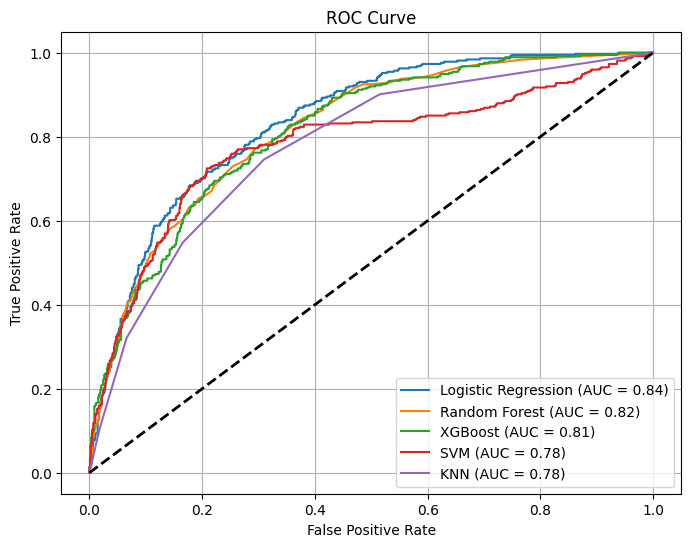

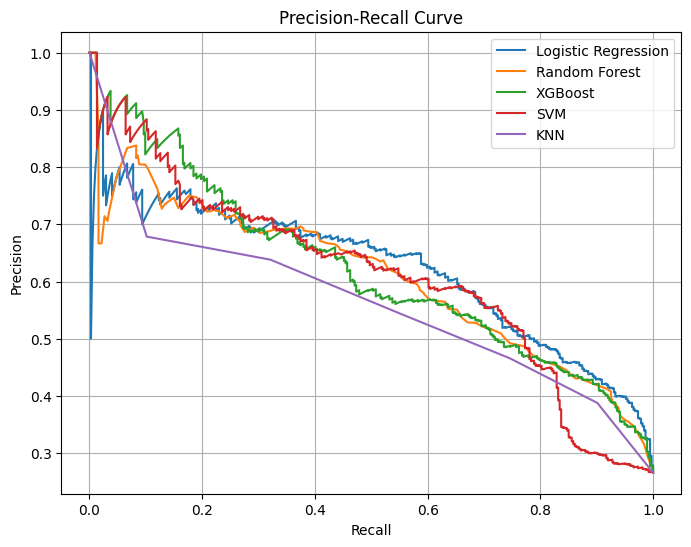

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc, precision_recall_curve

def plot_conf_matrix(y_test, y_pred, title="Confusion Matrix"):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(title)
    plt.show()

def plot_roc_curve(model, X_test, y_test, label=None):
    y_score = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_score)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{label} (AUC = {roc_auc:.2f})')

def plot_precision_recall(model, X_test, y_test, label=None):
    y_score = model.predict_proba(X_test)[:, 1]
    precision, recall, _ = precision_recall_curve(y_test, y_score)
    plt.plot(recall, precision, label=label)

# Plot ROC Curve for all models
plt.figure(figsize=(8, 6))
for name, model in models.items():
    plot_roc_curve(model, X_test, y_test, label=name)
plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid()
plt.show()

# Plot Precision-Recall Curve for all models
plt.figure(figsize=(8, 6))
for name, model in models.items():
    plot_precision_recall(model, X_test, y_test, label=name)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.grid()
plt.show()


In [8]:
import joblib

# Save the best model (replace with actual best)
best_model = models["Random Forest"]
joblib.dump(best_model, "churn_model.pkl")


['churn_model.pkl']

In [9]:
# Load the model
model = joblib.load("churn_model.pkl")

# Predict on new data
# new_customer = pd.DataFrame([some_data]) — make sure preprocessing matches training
# prediction = model.predict(new_customer)
# probability = model.predict_proba(new_customer)


In [10]:
!pip install streamlit


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 81.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 95.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 6.6 MB/s eta 0:00:00


In [11]:
# Save this as app.py
import streamlit as st
import joblib
import pandas as pd

model = joblib.load("churn_model.pkl")

st.title("Customer Churn Predictor")

# Collect input
tenure = st.slider("Tenure (months)", 0, 72)
monthly_charges = st.number_input("Monthly Charges")
total_charges = st.number_input("Total Charges")
# Add other inputs...

# On button click
if st.button("Predict Churn"):
    input_df = pd.DataFrame([[tenure, monthly_charges, total_charges]],
                            columns=["tenure", "MonthlyCharges", "TotalCharges"])
    # Add preprocessing as needed
    result = model.predict(input_df)[0]
    prob = model.predict_proba(input_df)[0][1]
    st.write(f"Churn: {'Yes' if result else 'No'}, Probability: {prob:.2f}")


In [15]:
# Churn_pipeline.py

import pandas as pd
import joblib
from sklearn.preprocessing import StandardScaler

class ChurnPredictor:
    def __init__(self, model_path):
        self.model = joblib.load(model_path)
        self.scaler = joblib.load("scaler.pkl")  # Save this during training
        self.numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
        self.expected_columns = joblib.load("columns.pkl")  # Save list of training columns

    def preprocess(self, input_data):
        # Input: dict or DataFrame of one customer
        df = pd.DataFrame([input_data]) if isinstance(input_data, dict) else input_data.copy()

        # Binary encode Yes/No fields
        binary_map = {"Yes": 1, "No": 0}
        binary_cols = ["Partner", "Dependents", "PhoneService", "PaperlessBilling"]
        for col in binary_cols:
            df[col] = df[col].map(binary_map)

        df["gender"] = df["gender"].map({"Male": 1, "Female": 0})
        df["SeniorCitizen"] = df["SeniorCitizen"].astype("category")

        # One-hot encoding
        multi_cat_cols = [
            "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
            "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
            "Contract", "PaymentMethod"
        ]
        df = pd.get_dummies(df, columns=multi_cat_cols)

        # Align with training columns
        for col in self.expected_columns:
            if col not in df.columns:
                df[col] = 0  # Add missing dummy columns
        df = df[self.expected_columns]

        # Scale numeric
        df[self.numeric_cols] = self.scaler.transform(df[self.numeric_cols])
        return df

    def predict(self, input_data):
        X = self.preprocess(input_data)
        prediction = self.model.predict(X)[0]
        probability = self.model.predict_proba(X)[0][1]
        return prediction, probability


In [13]:
# After scaling and encoding training data
joblib.dump(scaler, "scaler.pkl")
joblib.dump(X_train.columns.tolist(), "columns.pkl")
joblib.dump(models["Random Forest"], "churn_model.pkl")  # or best model


['churn_model.pkl']

In [16]:
# app.py

import streamlit as st
from churn_pipeline import ChurnPredictor

st.set_page_config(page_title="Churn Predictor", layout="centered")
model = ChurnPredictor("churn_model.pkl")

st.title("📉 Customer Churn Prediction")

# Collect inputs
gender = st.selectbox("Gender", ["Male", "Female"])
senior = st.selectbox("Senior Citizen", [0, 1])
partner = st.selectbox("Has Partner?", ["Yes", "No"])
dependents = st.selectbox("Has Dependents?", ["Yes", "No"])
tenure = st.slider("Tenure (months)", 0, 72)
phone = st.selectbox("Phone Service", ["Yes", "No"])
multi_lines = st.selectbox("Multiple Lines", ["No", "Yes", "No phone service"])
internet = st.selectbox("Internet Service", ["DSL", "Fiber optic", "No"])
online_sec = st.selectbox("Online Security", ["Yes", "No", "No internet service"])
online_bkp = st.selectbox("Online Backup", ["Yes", "No", "No internet service"])
device_protect = st.selectbox("Device Protection", ["Yes", "No", "No internet service"])
tech_supp = st.selectbox("Tech Support", ["Yes", "No", "No internet service"])
stream_tv = st.selectbox("Streaming TV", ["Yes", "No", "No internet service"])
stream_movies = st.selectbox("Streaming Movies", ["Yes", "No", "No internet service"])
contract = st.selectbox("Contract", ["Month-to-month", "One year", "Two year"])
paperless = st.selectbox("Paperless Billing", ["Yes", "No"])
payment = st.selectbox("Payment Method", [
    "Electronic check", "Mailed check",
    "Bank transfer (automatic)", "Credit card (automatic)"
])
monthly = st.number_input("Monthly Charges", min_value=0.0)
total = st.number_input("Total Charges", min_value=0.0)

if st.button("Predict Churn"):
    input_data = {
        "gender": gender,
        "SeniorCitizen": senior,
        "Partner": partner,
        "Dependents": dependents,
        "tenure": tenure,
        "PhoneService": phone,
        "MultipleLines": multi_lines,
        "InternetService": internet,
        "OnlineSecurity": online_sec,
        "OnlineBackup": online_bkp,
        "DeviceProtection": device_protect,
        "TechSupport": tech_supp,
        "StreamingTV": stream_tv,
        "StreamingMovies": stream_movies,
        "Contract": contract,
        "PaperlessBilling": paperless,
        "PaymentMethod": payment,
        "MonthlyCharges": monthly,
        "TotalCharges": total
    }

    prediction, prob = model.predict(input_data)
    label = "Churn" if prediction == 1 else "No Churn"
    st.markdown(f"### Prediction: **{label}**")
    st.progress(prob)
    st.markdown(f"Churn Probability: `{prob:.2f}`")


In [ ]:
!streamlit run app.py





  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.86.92.152:8501

  Stopping...
  Stopping...
